# Code Ownership, notebook 1: the data audit

Protocol: [PROTOCOL.md](../../PROTOCOL.md). The data: 36 real Python standard-library functions, one generated question each, 216 answers **written by the assistant at five
rubric levels** (no student wrote any of it, no human rated it). Nothing is fitted in this notebook.

In [1]:
import sys, warnings, json, pickle
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import ko_data as K, ko_models as M
from core import metrics, group_bootstrap, paired_diff_bootstrap, qwk, band
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = K.load()
dev = d[d.role == "dev"].reset_index(drop=True)
test = d[d.role == "test"].reset_index(drop=True)
y, groups, folds = dev.score.to_numpy(), dev.snippet_id.to_numpy(), dev.fold.to_numpy()
def ci(p, stat):
    return group_bootstrap(y, p, groups, stat, n=1000)
def sp(a, b):
    return spearmanr(a, b).correlation
def mae(a, b):
    return float(np.mean(np.abs(a - b)))
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

## 1. Size and structure

In [2]:
sizes = d.groupby("role").agg(answers=("item_id", "size"), functions=("snippet_id", "nunique"))
sizes.loc["total"] = sizes.sum()
print(sizes)
pd.crosstab(d.question_type, d.rating, margins=True)

       answers  functions
role                     
dev        178         30
test        38          6
total      216         36


rating,1,2,3,4,5,All
question_type,,,,,,
early_return,9,8,6,6,11,40
guard,7,8,7,6,10,38
handler,7,6,8,6,9,36
loop,6,8,7,6,9,36
purpose,6,7,7,6,8,34
return_value,7,6,6,6,7,32
All,42,43,41,36,54,216


## 2. The length confound

A scorer that only learns 'longer is better' would look good here and mean nothing. The first version of the answers had Spearman 0.83 between length and level; short correct and long weak answers were added (answers_extra.txt) before any model was fitted.

Spearman words vs written level, all answers: 0.503
{'early_return': 0.336, 'guard': 0.343, 'handler': 0.615, 'loop': 0.501, 'purpose': 0.733, 'return_value': 0.669}


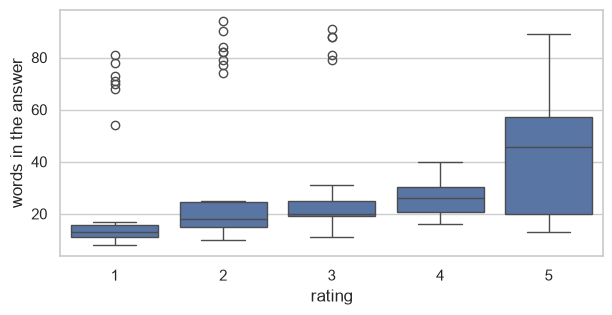

In [3]:
d["words"] = d.answer.str.split().str.len()
print("Spearman words vs written level, all answers:", round(sp(d.words, d.rating), 3))
print(d.groupby("question_type").apply(lambda g: round(sp(g.words, g.rating), 3)).to_dict())
fig, ax = plt.subplots(figsize=(7, 3.2)); sns.boxplot(data=d, x="rating", y="words", ax=ax); ax.set_ylabel("words in the answer"); plt.show()

## 3. How well do the written level and an independent rating agree?

`rating_independent` was given by a separate Claude instance that saw only a shuffled sheet without the levels. Both are model ratings, so agreement shows the levels are consistent and readable, not that humans would agree.

In [4]:
from sklearn.metrics import cohen_kappa_score
a, b = d.rating, d.rating_independent
agree = {"QWK": cohen_kappa_score(a, b, weights="quadratic"), "Spearman": sp(a, b), "exact": float((a == b).mean()), "within one": float((abs(a - b) <= 1).mean())}
print({k: round(v, 3) for k, v in agree.items()})
pd.crosstab(a, b, rownames=["written level"], colnames=["independent"])

{'QWK': 0.926, 'Spearman': np.float64(0.93), 'exact': 0.731, 'within one': 0.981}


independent,1,2,3,4,5
written level,,,,,
1,42,0,0,0,0
2,1,25,13,4,0
3,0,6,25,10,0
4,0,0,0,20,16
5,0,0,0,8,46


In [5]:
d[abs(a - b) >= 2][["item_id", "question_type", "rating", "rating_independent", "answer"]]

,item_id,question_type,rating,rating_independent,answer
187,K031-2a,return_value,2,4,"It returns sign and abs(q). q is computed with divmod(n + (d >> 1), d) and sign is n < 0."
192,K032-2a,return_value,2,4,"It returns self.copy(target, **kwargs). target is either target_dir / name or self.wit..."
209,K035-2a,return_value,2,4,"It returns key, value. key = link.key and value is from dict.pop(self, key) after dele..."
214,K036-2a,return_value,2,4,It returns ''.join(results) where results is a list that has strings appended through ...


## 4. The splits

Grouped by function. The final test functions are fixed by hash (one per question type) and are not looked at again until notebook 6.

In [6]:
print(d[d.role == "test"].groupby("question_type").snippet_id.first().to_dict())
dev.groupby("fold").agg(answers=("item_id", "size"), functions=("snippet_id", "nunique"))

{'early_return': 'K015', 'guard': 'K005', 'handler': 'K007', 'loop': 'K019', 'purpose': 'K025', 'return_value': 'K032'}


,answers,functions
fold,,
0,40,6
1,36,6
2,32,6
3,34,6
4,36,6


## 5. Reading the results

**What the data is.** 36 real Python standard-library functions, one generated question each, 216 answers written by the assistant at five rubric levels (42 / 43 / 41 / 36 / 54 answers at levels 1 to 5). No student wrote any of it and no human rated it.

**The length confound was checked and reduced.** The first version had Spearman 0.83 between answer length and level; after adding short correct and long weak answers it is 0.50 (0.34 to 0.73 inside the question types). Length still carries real signal, as it does in human grading, and the baselines in notebook 2 show it.

**Rater agreement.** A separate Claude instance that saw only a shuffled sheet without levels agreed with the written levels at QWK 0.93, Spearman 0.93, 73% exactly and 98% within one level. Only 4 answers differ by two levels (all four are short "restates the return statement" answers the independent rater scored 4 and the written level 2). Both are model judgements with correlated habits: the agreement shows the levels are readable, not that humans would agree.

**Splits.** 30 development functions (178 answers) in 5 folds of 6 functions (one of each question type per fold), and 6 final-test functions (38 answers, one per question type), fixed by hash.
